<a href="https://colab.research.google.com/github/PARODBE/Clase/blob/main/EDA_Stroke.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#ANÁLISIS EXPLORATORIO DE DATOS SOBRE INFARTOS

1) Análisis del riesgo de infarto por género y edad.

2) Cómo influyen los niveles de glucosa en la aparición de infartos?

3) Una persona con una enfermedad cardíaca o hipertensión tiene más riesgo de sufrir un infarto?

4) Análisis del estilo de vida. Se observa causalidad entre con el estado civil? Con el tipo de trabajo? Con el área donde vive?

5) Cómo influye el tabaco en la aparición de infartos?



In [ ]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

df = pd.read_csv("https://gist.githubusercontent.com/aishwarya8615/d2107f828d3f904839cbcb7eaa85bd04/raw/cec0340503d82d270821e03254993b6dede60afb/healthcare-dataset-stroke-data.csv")

In [ ]:
df

,id,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
0,9046,Male,67.0,0,1,Yes,Private,Urban,228.69,36.6,formerly smoked,1
1,51676,Female,61.0,0,0,Yes,Self-employed,Rural,202.21,NaN,never smoked,1
2,31112,Male,80.0,0,1,Yes,Private,Rural,105.92,32.5,never smoked,1
3,60182,Female,49.0,0,0,Yes,Private,Urban,171.23,34.4,smokes,1
4,1665,Female,79.0,1,0,Yes,Self-employed,Rural,174.12,24.0,never smoked,1
...,...,...,...,...,...,...,...,...,...,...,...,...
5105,18234,Female,80.0,1,0,Yes,Private,Urban,83.75,NaN,never smoked,0
5106,44873,Female,81.0,0,0,Yes,Self-employed,Urban,125.20,40.0,never smoked,0
5107,19723,Female,35.0,0,0,Yes,Self-employed,Rural,82.99,30.6,never smoked,0
5108,37544,Male,51.0,0,0,Yes,Private,Rural,166.29,25.6,formerly smoked,0


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5110 entries, 0 to 5109
Data columns (total 12 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   id                 5110 non-null   int64  
 1   gender             5110 non-null   object 
 2   age                5110 non-null   float64
 3   hypertension       5110 non-null   int64  
 4   heart_disease      5110 non-null   int64  
 5   ever_married       5110 non-null   object 
 6   work_type          5110 non-null   object 
 7   Residence_type     5110 non-null   object 
 8   avg_glucose_level  5110 non-null   float64
 9   bmi                4909 non-null   float64
 10  smoking_status     5110 non-null   object 
 11  stroke             5110 non-null   int64  
dtypes: float64(3), int64(4), object(5)
memory usage: 479.2+ KB


In [ ]:
df.describe(include="all")

,id,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
count,5110.000000,5110,5110.000000,5110.000000,5110.000000,5110,5110,5110,5110.000000,4909.000000,5110,5110.000000
unique,NaN,3,NaN,NaN,NaN,2,5,2,NaN,NaN,4,NaN
top,NaN,Female,NaN,NaN,NaN,Yes,Private,Urban,NaN,NaN,never smoked,NaN
freq,NaN,2994,NaN,NaN,NaN,3353,2925,2596,NaN,NaN,1892,NaN
mean,36517.829354,NaN,43.226614,0.097456,0.054012,NaN,NaN,NaN,106.147677,28.893237,NaN,0.048728
std,21161.721625,NaN,22.612647,0.296607,0.226063,NaN,NaN,NaN,45.283560,7.854067,NaN,0.215320
min,67.000000,NaN,0.080000,0.000000,0.000000,NaN,NaN,NaN,55.120000,10.300000,NaN,0.000000
25%,17741.250000,NaN,25.000000,0.000000,0.000000,NaN,NaN,NaN,77.245000,23.500000,NaN,0.000000
50%,36932.000000,NaN,45.000000,0.000000,0.000000,NaN,NaN,NaN,91.885000,28.100000,NaN,0.000000
75%,54682.000000,NaN,61.000000,0.000000,0.000000,NaN,NaN,NaN,114.090000,33.100000,NaN,0.000000


In [ ]:
# Clasicamos por variables categoricas y numericas (descarta id)
df_num=df[['age','avg_glucose_level','bmi']]
df_cat=df[['gender', 'hypertension', 'heart_disease', 'ever_married','work_type', 'Residence_type', 'smoking_status', 'stroke']]

In [ ]:
# Añadimos el IQR a las numericas
desc = df_num.describe()
desc.loc["IQR"] = desc.loc["75%"] - desc.loc["25%"]
desc.loc["min_outlier"] = desc.loc["25%"] - 1.5*desc.loc["IQR"]
desc.loc["max_outlier"] = desc.loc["75%"] + 1.5*desc.loc["IQR"]
desc

,age,avg_glucose_level,bmi
count,5110.000000,5110.000000,4909.000000
mean,43.226614,106.147677,28.893237
std,22.612647,45.283560,7.854067
min,0.080000,55.120000,10.300000
25%,25.000000,77.245000,23.500000
50%,45.000000,91.885000,28.100000
75%,61.000000,114.090000,33.100000
max,82.000000,271.740000,97.600000
IQR,36.000000,36.845000,9.600000
min_outlier,-29.000000,21.977500,9.100000


Análisis de outliers

In [ ]:
# Candidatos a outlier por el método IQR

candidates_iqr = {}
for col in df_num.columns:
  candidates_iqr[col] = df[(df[col] < desc.loc["min_outlier", col]) | (df[col] > desc.loc["max_outlier", col])].copy()
  print(f"Candidatos {col}: {len(candidates_iqr[col])}")

Candidatos age: 0
Candidatos avg_glucose_level: 627
Candidatos bmi: 110


##Análisis EDAD

In [ ]:
# No hay candidatos por IQR, pero puede haber outliers igual?

df_num.sort_values("age")

,age,avg_glucose_level,bmi
1614,0.08,139.67,14.1
3295,0.08,70.33,16.9
3618,0.16,114.71,17.4
3968,0.16,69.79,13.0
4021,0.16,109.52,13.9
...,...,...,...
56,82.00,59.32,33.2
4094,82.00,111.81,19.8
4088,82.00,88.60,32.5
4164,82.00,222.52,NaN


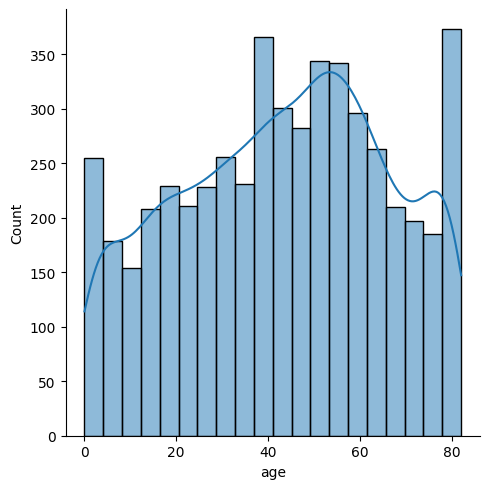

In [ ]:
sns.displot(df_num.age, kde=True)

In [ ]:
# Vamos a explorar qué pasa con los decimales

# Opción sin apply. Se aplica np.floor a la columna, pero como devueve un array, hay que trasnformarlo a pd.Series para operar con df.age
#check_int = df.age - pd.Series(np.floor(df.age))

check_int = df.age - df.age.apply(np.floor)
check_int[check_int > 0]

,age
162,0.32
363,0.64
376,0.88
562,0.80
564,0.32
...,...
4934,0.32
5032,0.24
5079,0.72
5089,0.72


In [ ]:
df[df.age == 1]

,id,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
844,47876,Male,1.0,0,0,No,children,Rural,89.30,21.4,Unknown,0
951,57372,Male,1.0,0,0,No,children,Rural,123.21,15.1,Unknown,0
1432,12687,Male,1.0,0,0,No,children,Urban,101.31,18.3,Unknown,0
1794,46035,Male,1.0,0,0,No,children,Urban,84.85,20.3,Unknown,0
2240,54985,Female,1.0,0,0,No,children,Urban,199.83,24.5,Unknown,0


In [ ]:
# Maxima edad con decimales
df.loc[check_int[check_int > 0].index, "age"].max()

1.88

In [ ]:
# Numero de infartos en esos registros de edad rara
registros_perdidos = len(df.loc[(check_int[check_int > 0].index), "stroke"].loc[df.stroke==1])
registros_totales = sum(df.stroke==1)
print(f"Descartando las edades decimales perdemos {registros_perdidos} registros de un total de {registros_totales}, un {registros_perdidos/registros_totales:.2%}")

Descartando las edades decimales perdemos 1 registros de un total de 249, un 0.40%


In [ ]:
# Numero de infartos en esos registros de edad 0-1
registros_perdidos = len(df.loc[df.age < 2, "stroke"].loc[df.stroke==1])
registros_totales = sum(df.stroke==1)
print(f"Descartando las edades decimales perdemos {registros_perdidos} registros de un total de {registros_totales}, un {registros_perdidos/registros_totales:.2%}")

Descartando las edades decimales perdemos 1 registros de un total de 249, un 0.40%


In [ ]:
len(df[df.age.astype(int) == 82])

56

In [ ]:
len(df[df.age.astype(int) == 81])

60

In [ ]:
len(df[df.age.astype(int) == 80])

70

In [ ]:
len(df[df.age == 79.0])

85

In [ ]:
len(df[df.age == 49.0])

79

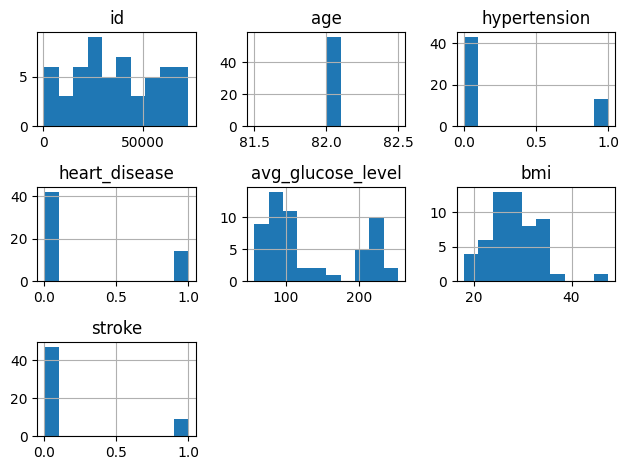

In [ ]:
# A ver que pasa con los 82 años
df[df.age == 82].hist()
plt.tight_layout()

No hay información suficiente ni para descartarlos ni para imputarlos. Parecen proceder de un procesado previo de tipo winsorize...

##Análisis BMI

In [ ]:
candidates_iqr["bmi"].sort_values("bmi")

,id,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
5057,38349,Female,49.0,0,0,Yes,Govt_job,Urban,69.92,47.6,never smoked,0
4405,68853,Female,70.0,0,0,Yes,Private,Rural,149.80,47.6,Unknown,0
4858,1696,Female,43.0,0,0,Yes,Private,Urban,100.88,47.6,smokes,0
622,39601,Female,33.0,0,0,Yes,Private,Urban,69.40,47.8,never smoked,0
4847,52978,Female,30.0,0,0,Yes,Private,Urban,84.92,47.8,never smoked,0
...,...,...,...,...,...,...,...,...,...,...,...,...
1559,37759,Female,53.0,0,0,Yes,Private,Rural,72.63,66.8,Unknown,0
544,545,Male,42.0,0,0,Yes,Private,Rural,210.48,71.9,never smoked,0
928,41097,Female,23.0,1,0,No,Private,Urban,70.03,78.0,smokes,0
4209,51856,Male,38.0,1,0,Yes,Private,Rural,56.90,92.0,never smoked,0


<Axes: >

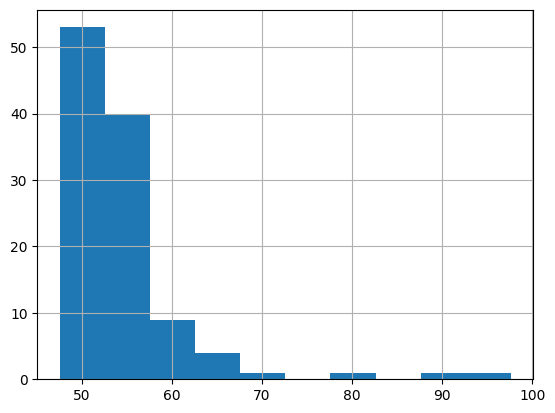

In [ ]:
candidates_iqr["bmi"]["bmi"].hist()

In [ ]:
df.nlargest(4, columns="bmi")

,id,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
2128,56420,Male,17.0,1,0,No,Private,Rural,61.67,97.6,Unknown,0
4209,51856,Male,38.0,1,0,Yes,Private,Rural,56.90,92.0,never smoked,0
928,41097,Female,23.0,1,0,No,Private,Urban,70.03,78.0,smokes,0
544,545,Male,42.0,0,0,Yes,Private,Rural,210.48,71.9,never smoked,0


In [ ]:
# El bmi es el peso(kg)/altura(m)^2
# Vamos a ver que implica un bmi de 97.6 por ejemplo

heights = np.linspace(1,2,3)
top4_bmi = candidates_iqr["bmi"].nlargest(4, columns="bmi")["bmi"]
for bmi in top4_bmi:
  print(f"BMI={bmi}")
  for h in heights:
    weight = bmi*h**2
    print(f"Para una altura de {h}m supone pesar {weight}kg")


BMI=97.6
Para una altura de 1.0m supone pesar 97.6kg
Para una altura de 1.5m supone pesar 219.6kg
Para una altura de 2.0m supone pesar 390.4kg
BMI=92.0
Para una altura de 1.0m supone pesar 92.0kg
Para una altura de 1.5m supone pesar 207.0kg
Para una altura de 2.0m supone pesar 368.0kg
BMI=78.0
Para una altura de 1.0m supone pesar 78.0kg
Para una altura de 1.5m supone pesar 175.5kg
Para una altura de 2.0m supone pesar 312.0kg
BMI=71.9
Para una altura de 1.0m supone pesar 71.9kg
Para una altura de 1.5m supone pesar 161.775kg
Para una altura de 2.0m supone pesar 287.6kg


**Decido eliminar el top4 de los candidatos a outliers**

In [ ]:
# Reviso posibles outliers por debajo, aunque no sean candidatos via IQR

heights = np.linspace(0.5,2,4)
bottom4_bmi = df_num.nsmallest(4, columns="bmi")["bmi"]
for bmi in bottom4_bmi:
  print(f"BMI={bmi}")
  for h in heights:
    weight = bmi*h**2
    print(f"Para una altura de {h}m supone pesar {weight}kg")

BMI=10.3
Para una altura de 0.5m supone pesar 2.575kg
Para una altura de 1.0m supone pesar 10.3kg
Para una altura de 1.5m supone pesar 23.175kg
Para una altura de 2.0m supone pesar 41.2kg
BMI=11.3
Para una altura de 0.5m supone pesar 2.825kg
Para una altura de 1.0m supone pesar 11.3kg
Para una altura de 1.5m supone pesar 25.425kg
Para una altura de 2.0m supone pesar 45.2kg
BMI=11.5
Para una altura de 0.5m supone pesar 2.875kg
Para una altura de 1.0m supone pesar 11.5kg
Para una altura de 1.5m supone pesar 25.875kg
Para una altura de 2.0m supone pesar 46.0kg
BMI=12.0
Para una altura de 0.5m supone pesar 3.0kg
Para una altura de 1.0m supone pesar 12.0kg
Para una altura de 1.5m supone pesar 27.0kg
Para una altura de 2.0m supone pesar 48.0kg


In [ ]:
df_num.nsmallest(4, columns="bmi")

,age,avg_glucose_level,bmi
1609,1.24,122.04,10.3
3307,79.00,79.03,11.3
2187,40.00,60.96,11.5
657,4.00,107.25,12.0


##Análisis glucosa

In [ ]:
candidates_iqr["avg_glucose_level"].sort_values("avg_glucose_level")


,id,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
2637,2005,Male,78.0,0,1,Yes,Self-employed,Urban,169.43,23.5,formerly smoked,0
2166,61291,Male,28.0,0,0,Yes,Private,Rural,169.49,27.2,Unknown,0
150,11933,Female,79.0,0,0,Yes,Private,Rural,169.67,NaN,Unknown,1
3224,36744,Male,40.0,0,0,Yes,Self-employed,Rural,169.74,31.9,never smoked,0
1428,46373,Female,57.0,0,0,Yes,Private,Rural,169.97,25.8,never smoked,0
...,...,...,...,...,...,...,...,...,...,...,...,...
2462,27626,Female,60.0,0,0,No,Govt_job,Rural,266.59,25.5,never smoked,0
4983,10995,Male,76.0,1,0,Yes,Private,Rural,267.60,30.5,never smoked,0
3088,26267,Female,76.0,0,0,Yes,Self-employed,Urban,267.61,27.9,smokes,0
1207,22440,Female,49.0,0,0,Yes,Private,Urban,267.76,29.3,formerly smoked,0


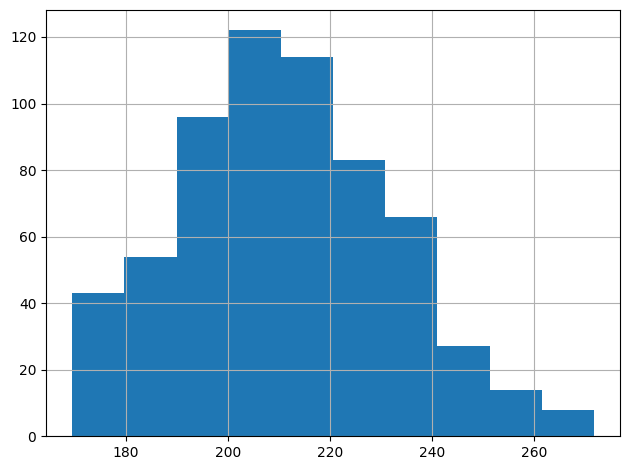

In [ ]:
candidates_iqr["avg_glucose_level"]["avg_glucose_level"].hist()
plt.tight_layout()

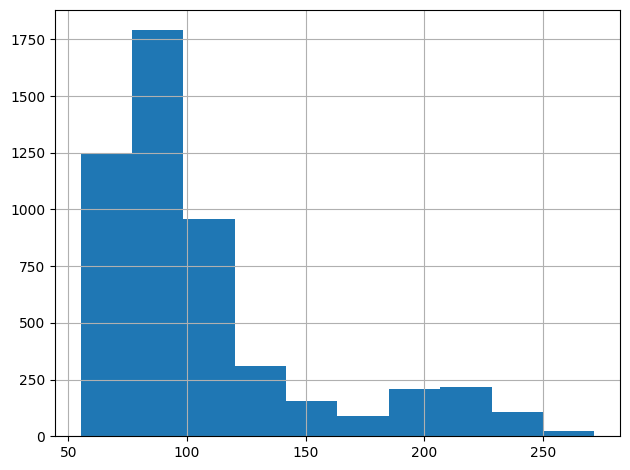

In [ ]:
df["avg_glucose_level"].hist()
plt.tight_layout()

In [ ]:
from scipy.stats import gaussian_kde

kde = [0]
derivadas = [0]
for i in range(3000):
  new_val = gaussian_kde(df.avg_glucose_level.values).pdf(i/10)[0]
  kde.append(new_val)
  derivada = (kde[-1]-kde[-2])/0.1
  derivadas.append(derivada)
  if derivadas[-1] > 0 and derivadas[-2] < 0:
    print(i/10)

172.4


<Axes: >

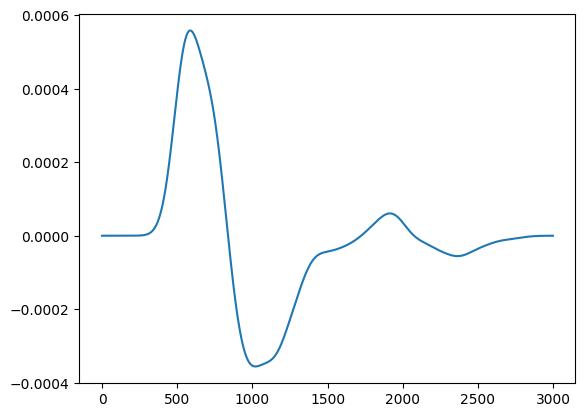

In [ ]:
sns.lineplot(derivadas)

**No descarto nada en la glucosa**

# Decido eliminar los outliers

In [ ]:
top_outliers_bmi = df_num.nlargest(4, columns="bmi")
bottom_outliers_bmi = df_num.nsmallest(4, columns="bmi").loc[df_num.age > 5] # excluimos niños donde podria tener sentido ese bmi
outliers_edad_decimal = df_num.loc[(df_num.age < 2) & (df_num.age != 1)]

outliers = pd.concat([top_outliers_bmi, bottom_outliers_bmi, outliers_edad_decimal])
outliers

,age,avg_glucose_level,bmi
2128,17.00,61.67,97.6
4209,38.00,56.90,92.0
928,23.00,70.03,78.0
544,42.00,210.48,71.9
3307,79.00,79.03,11.3
...,...,...,...
4934,1.32,107.02,NaN
5032,1.24,61.94,20.3
5079,1.72,77.28,17.1
5089,0.72,62.13,16.8


In [ ]:
# Reasigno el df de entrada, eliminando estos outliers y  también elimino el id
# Esto modifica los estadísticos

df = df.drop(columns="id").iloc[~df.index.isin(outliers.index),:]

In [ ]:
df.describe(include="all")

,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
count,4989,4989.000000,4989.000000,4989.000000,4989,4989,4989,4989.000000,4794.000000,4989,4989.000000
unique,3,NaN,NaN,NaN,2,5,2,NaN,NaN,4,NaN
top,Female,NaN,NaN,NaN,Yes,Private,Urban,NaN,NaN,never smoked,NaN
freq,2936,NaN,NaN,NaN,3349,2920,2535,NaN,NaN,1889,NaN
mean,NaN,44.201042,0.099218,0.055322,NaN,NaN,NaN,106.421149,29.092136,NaN,0.049709
std,NaN,21.941717,0.298985,0.228630,NaN,NaN,NaN,45.548581,7.589150,NaN,0.217366
min,NaN,1.000000,0.000000,0.000000,NaN,NaN,NaN,55.120000,12.000000,NaN,0.000000
25%,NaN,27.000000,0.000000,0.000000,NaN,NaN,NaN,77.420000,23.900000,NaN,0.000000
50%,NaN,45.000000,0.000000,0.000000,NaN,NaN,NaN,91.950000,28.200000,NaN,0.000000
75%,NaN,61.000000,0.000000,0.000000,NaN,NaN,NaN,114.180000,33.200000,NaN,0.000000


# Imputar nulos en bmi

In [ ]:
df.bmi.isna().sum()

195

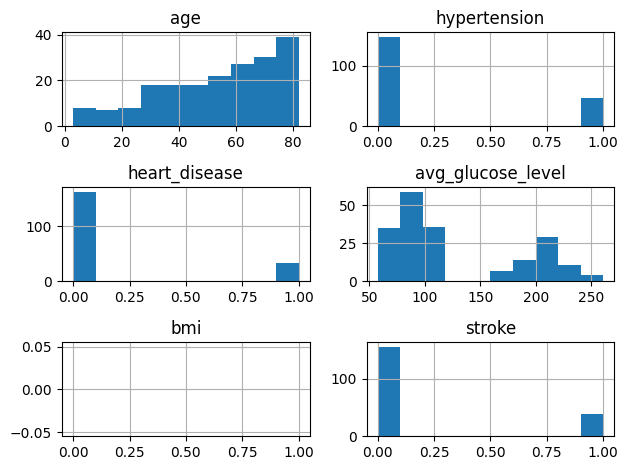

In [ ]:
# Vamos a explorar que les pasa a esos nulos

df[df.bmi.isna()].hist()
plt.tight_layout()

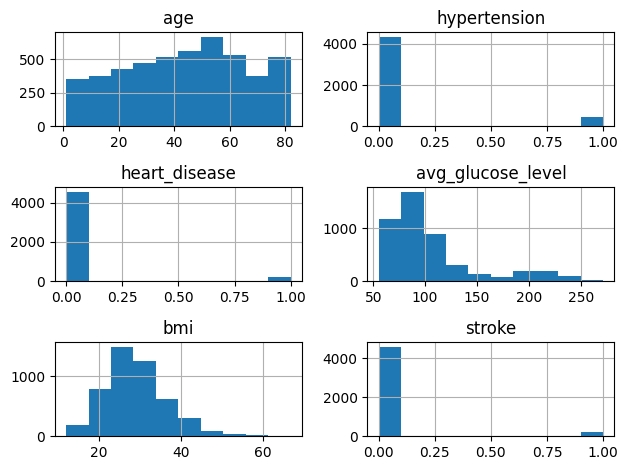

In [ ]:
# Vamos a explorar que les pasa a esos nulos

df[~df.bmi.isna()].hist()
plt.tight_layout()

In [ ]:
infartos_en_nulos = df.loc[df.bmi.isna(), "stroke"].value_counts(normalize=True).iloc[1]
infartos_en_nonulos = df.loc[~df.bmi.isna(), "stroke"].value_counts(normalize=True).iloc[1]

print(f"En los casos de bmi nulo se detectan {infartos_en_nulos:.2%}, mientras que en los no nulos se detectan {infartos_en_nonulos:.2%}")

En los casos de bmi nulo se detectan 20.00%, mientras que en los no nulos se detectan 4.36%


In [ ]:
bmi_when_stroke = df.loc[df.stroke == 1, "bmi"].mean()
bmi_when_nostroke = df.loc[df.stroke == 0, "bmi"].mean()

print(f"En los casos de infarto la media de bmi es {bmi_when_stroke} y en los de no infarto es {bmi_when_nostroke}")

En los casos de infarto la media de bmi es 30.471291866028707 y en los de no infarto es 29.029269356597602


<Axes: xlabel='glucose_over150', ylabel='bmi'>

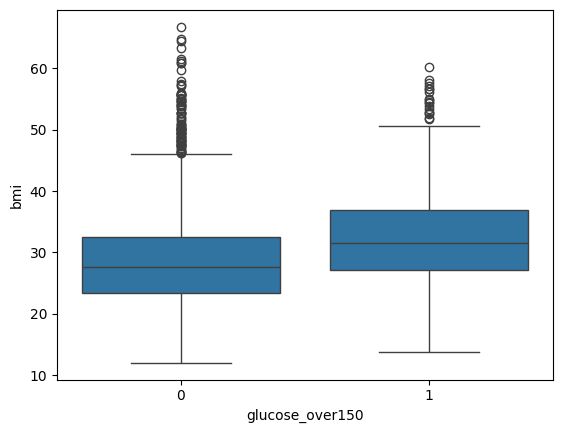

In [ ]:
bmi_glucose = df.loc[~df.bmi.isna(), ["avg_glucose_level", "bmi"]].copy()
bmi_glucose["glucose_over150"] = (bmi_glucose.avg_glucose_level > 150).astype(int)
sns.boxplot(bmi_glucose, x="glucose_over150", y="bmi")

In [ ]:
print(f"MODA: {df.bmi.mode()}")
print(f"MEDIA: {df.bmi.mean()}")
print(f"MEDIANA: {df.bmi.median()}")

MODA: 0    28.7
Name: bmi, dtype: float64
MEDIA: 29.092136003337508
MEDIANA: 28.2


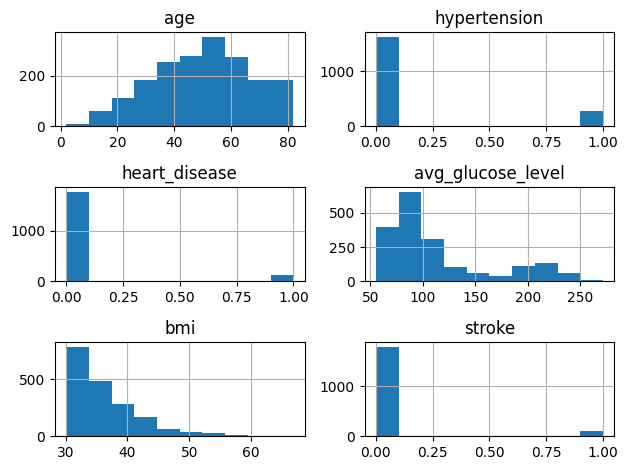

In [ ]:
df[(df.bmi > 30)].hist()
plt.tight_layout()

<Axes: xlabel='bmi', ylabel='Count'>

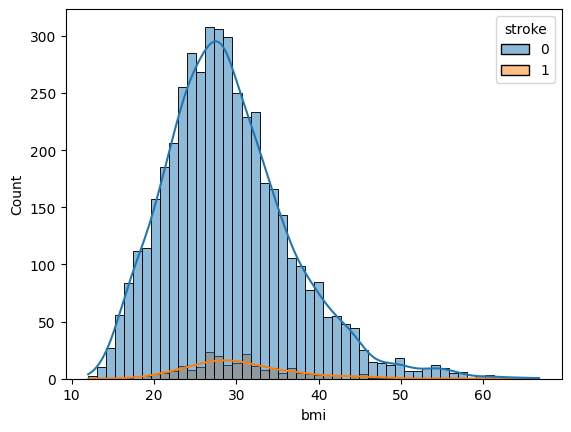

In [ ]:
sns.histplot(df, x="bmi", hue="stroke", kde=True)

In [ ]:
# No se ve gran patrón -> Imputamos la media para no perder registros positivos

df.loc[df.bmi.isna(), "bmi"] = df.bmi.mean()

In [ ]:
df.bmi.describe()

,bmi
count,4989.000000
mean,29.092136
std,7.439326
min,12.000000
25%,24.100000
50%,28.600000
75%,32.900000
max,66.800000


# Análisis del género

In [ ]:
df.gender.value_counts()

,count
gender,
Female,2936
Male,2052
Other,1


In [ ]:
df.loc[df.gender == "Other", :]

,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
3116,Other,26.0,0,0,No,Private,Rural,143.33,22.4,formerly smoked,0


In [ ]:
gender_stroke = pd.crosstab(df.loc[df.gender != "Other", "stroke"], df.loc[df.gender != "Other", "gender"], margins=True)
gender_stroke

gender,Female,Male,All
stroke,,,
0,2796,1944,4740
1,140,108,248
All,2936,2052,4988


In [ ]:
from scipy.stats.contingency import relative_risk

res = relative_risk(gender_stroke.loc[1, "Male"],
                    gender_stroke.loc["All", "Male"],
                    gender_stroke.loc[1, "Female"],
                    gender_stroke.loc["All", "Female"])
res

RelativeRiskResult(relative_risk=1.1037593984962404, exposed_cases=108, exposed_total=2052, control_cases=140, control_total=2936)

In [ ]:
(108/2052)/(140/2936)

1.1037593984962404

In [ ]:
res.confidence_interval(confidence_level=0.95)

ConfidenceInterval(low=np.float64(0.864265882512056), high=np.float64(1.4096180752012826))

In [ ]:
res.confidence_interval(confidence_level=0.57)

ConfidenceInterval(low=np.float64(1.0002335924393946), high=np.float64(1.2180002941088983))

In [ ]:
print(f'Infartos en hombres {gender_stroke.loc[1, "Male"]/gender_stroke.loc["All", "Male"]:.2%}')
print(f'Infartos en mujeres {gender_stroke.loc[1, "Female"]/gender_stroke.loc["All", "Female"]:.2%}')

Infartos en hombres 5.26%
Infartos en mujeres 4.77%


**Se ve ligero riesgo extra a sufrir infarto para los hombres**

# Analisis por edad

<Axes: xlabel='age', ylabel='Density'>

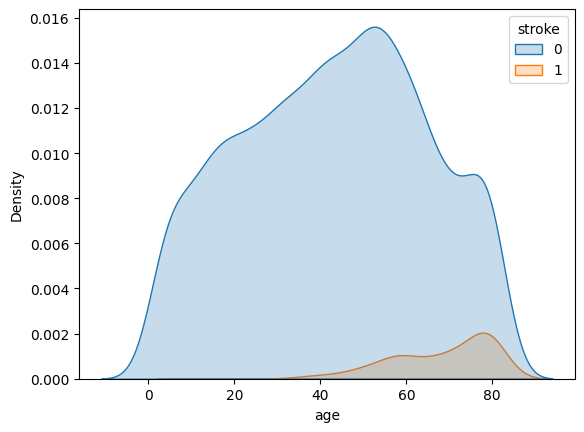

In [ ]:
sns.kdeplot(df, x="age", hue="stroke", fill=True)

In [ ]:
# Minima edad de infarto

df.loc[df.stroke == 1, :].sort_values("age")

,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
245,Female,14.0,0,0,No,children,Rural,57.93,30.900000,Unknown,1
182,Female,32.0,0,0,Yes,Private,Rural,76.13,29.900000,smokes,1
118,Female,38.0,0,0,No,Self-employed,Urban,82.28,24.000000,formerly smoked,1
133,Female,38.0,0,0,Yes,Private,Rural,101.45,29.092136,formerly smoked,1
210,Female,39.0,0,0,Yes,Private,Urban,83.24,26.300000,never smoked,1
...,...,...,...,...,...,...,...,...,...,...,...
23,Male,82.0,0,1,Yes,Private,Rural,208.30,32.500000,Unknown,1
187,Female,82.0,1,1,Yes,Govt_job,Urban,215.94,27.900000,formerly smoked,1
188,Male,82.0,0,0,Yes,Private,Rural,86.62,29.500000,formerly smoked,1
140,Male,82.0,0,1,Yes,Govt_job,Rural,103.68,25.000000,never smoked,1


<Axes: xlabel='age', ylabel='Density'>

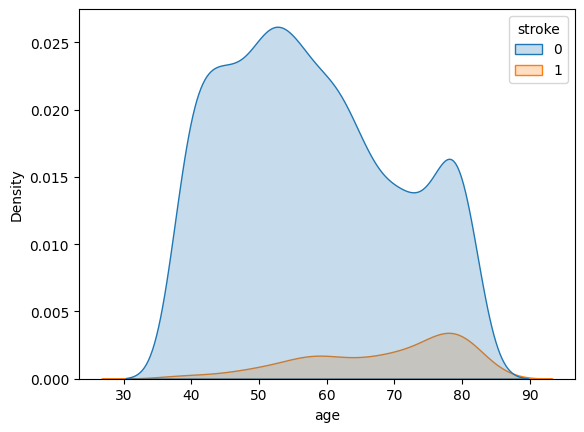

In [ ]:
# Veamos las distribuciones para edad > 37

sns.kdeplot(df[df.age > 37], x="age", hue="stroke", fill=True)

<Axes: xlabel='stroke', ylabel='age'>

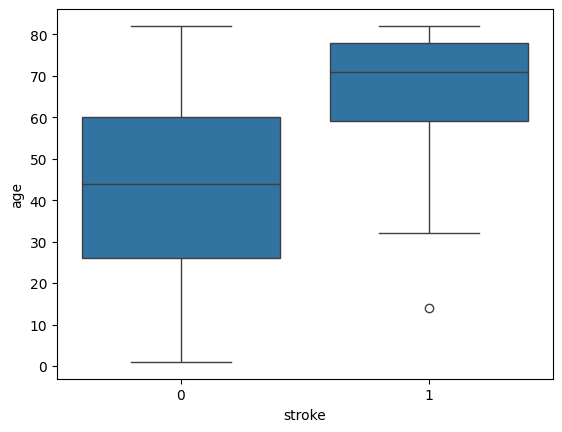

In [ ]:
sns.boxplot(df, x="stroke", y="age")

Clara causalidad entre la edad y el riesgo de infarto. La mediana sube de unos 45 años a unos 70. Además el Q1 de los infartos está al mismo nivel que el Q3 de los sanos.

<Axes: xlabel='stroke', ylabel='age'>

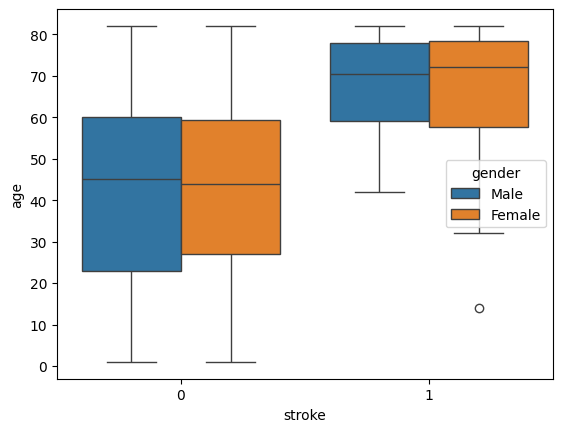

In [ ]:
# BONUS: Combinación edad-genero-infarto (trivariante)

sns.boxplot(df[df.gender != "Other"], x="stroke", y="age", hue="gender")

Distribuciones muy similares. Quizás en mujeres hay más casos en jóvenes, aunque la mayoría de los casos suceden ligeramente después que en hombres.

#Análisis de la glucosa

<Axes: xlabel='avg_glucose_level', ylabel='Density'>

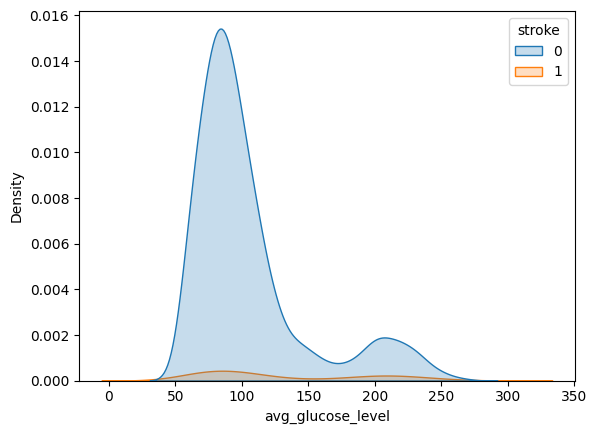

In [ ]:
sns.kdeplot(df, x="avg_glucose_level", hue="stroke", fill=True)

<Axes: xlabel='avg_glucose_level', ylabel='Proportion'>

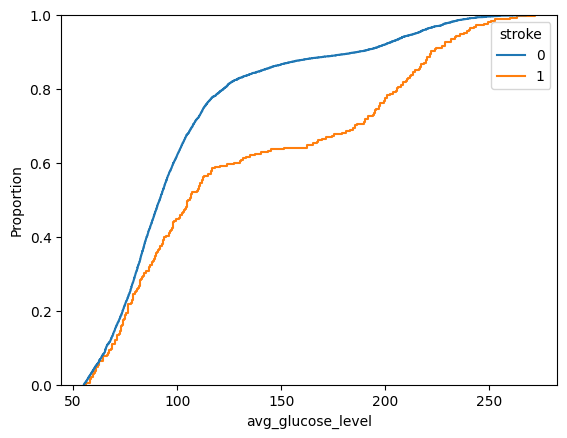

In [ ]:
sns.ecdfplot(df, x="avg_glucose_level", hue="stroke")

<Axes: xlabel='stroke', ylabel='avg_glucose_level'>

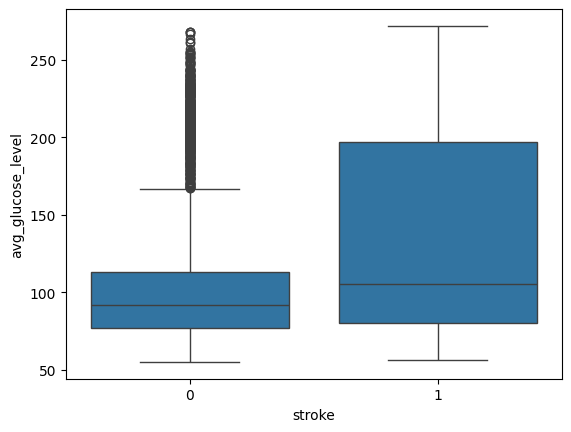

In [ ]:
sns.boxplot(df, x="stroke", y="avg_glucose_level")

No se aprecia una causalidad evidente, aunque sí se ve que en los casos de infarto los niveles de glucosa son ligeramente superiores. En la distribución de probabilidad se ve una pendiente más alta en los últimos niveles de glucosa y un valle entre 100-200. Hagamos zoom en esos grupos

<Axes: xlabel='stroke', ylabel='avg_glucose_level'>

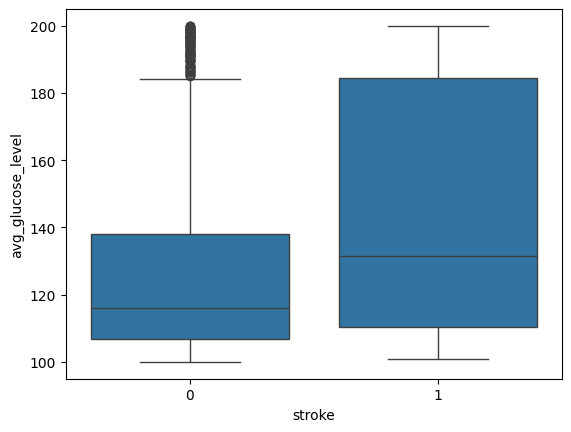

In [ ]:
sns.boxplot(df.loc[(df.avg_glucose_level > 100) & (df.avg_glucose_level < 200)], x="stroke", y="avg_glucose_level")

<Axes: xlabel='stroke', ylabel='avg_glucose_level'>

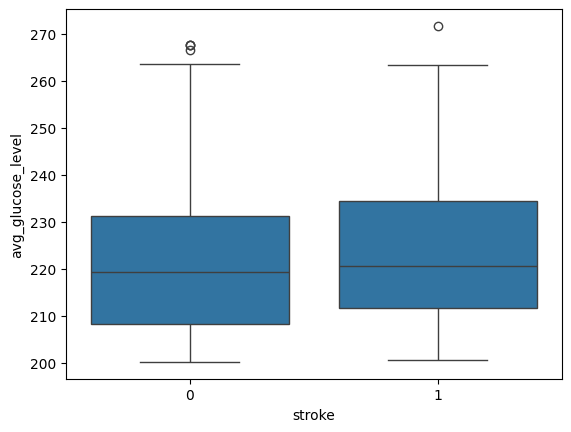

In [ ]:
sns.boxplot(df.loc[df.avg_glucose_level >= 200], x="stroke", y="avg_glucose_level")

Parece que los niveles intermedios de glucosa se relacionan con una cantidad más alta de infartos

# Análisis hipertensión y enfermedad cardiaca

In [ ]:
# Lo haremos con la estadística de asociacion del riesgo relativo

hypert_stroke = pd.crosstab(df.stroke, df.hypertension, margins=True)
hypert_stroke

hypertension,0,1,All
stroke,,,
0,4312,429,4741
1,182,66,248
All,4494,495,4989


In [ ]:
res = relative_risk(hypert_stroke.loc[1, 1],
                    hypert_stroke.loc["All", 1],
                    hypert_stroke.loc[1, 0],
                    hypert_stroke.loc["All", 0])
res

RelativeRiskResult(relative_risk=3.2923076923076926, exposed_cases=66, exposed_total=495, control_cases=182, control_total=4494)

In [ ]:
res.confidence_interval(confidence_level=0.95)

ConfidenceInterval(low=2.523640387697251, high=4.295100836739637)

In [ ]:
res.confidence_interval(confidence_level=0.99999)

ConfidenceInterval(low=1.808251702464565, high=5.994347980458111)

In [ ]:
heart_stroke = pd.crosstab(df.stroke, df.heart_disease, margins=True)
heart_stroke

heart_disease,0,1,All
stroke,,,
0,4512,229,4741
1,201,47,248
All,4713,276,4989


In [ ]:
res = relative_risk(heart_stroke.loc[1, 1],
                    heart_stroke.loc["All", 1],
                    heart_stroke.loc[1, 0],
                    heart_stroke.loc["All", 0])
res

RelativeRiskResult(relative_risk=3.992915855505083, exposed_cases=47, exposed_total=276, control_cases=201, control_total=4713)

In [ ]:
res.confidence_interval()

ConfidenceInterval(low=np.float64(2.977470611759581), high=np.float64(5.3546715007614845))

**Con una confianza del 95%, hay un riesgo de x2.52 de tener infarto con hipertensión y un riesgo de x3 de tener infarto con enfermedad cardiaca previa**

#Analisis estilo de vida

In [ ]:
df.work_type.value_counts()

,count
work_type,
Private,2920
Self-employed,818
Govt_job,657
children,572
Never_worked,22


In [ ]:
df.work_type.value_counts(normalize=True)

,proportion
work_type,
Private,0.585288
Self-employed,0.163961
Govt_job,0.131690
children,0.114652
Never_worked,0.004410


In [ ]:
df.Residence_type.value_counts()

,count
Residence_type,
Urban,2535
Rural,2454


In [ ]:
df.ever_married.value_counts()

,count
ever_married,
Yes,3349
No,1640


<Axes: xlabel='work_type', ylabel='count'>

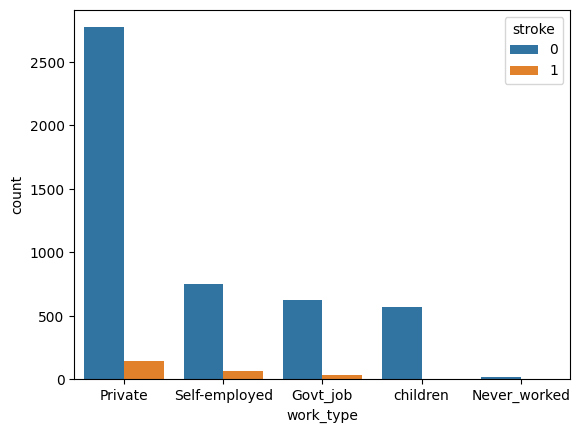

In [ ]:
sns.countplot(df, x="work_type", hue="stroke")

<Axes: xlabel='work_type', ylabel='percent'>

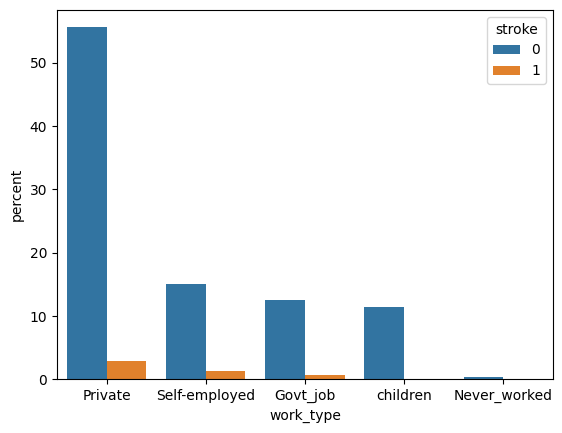

In [ ]:
sns.countplot(df, x="work_type", hue="stroke", stat="percent")

<Axes: xlabel='work_type'>

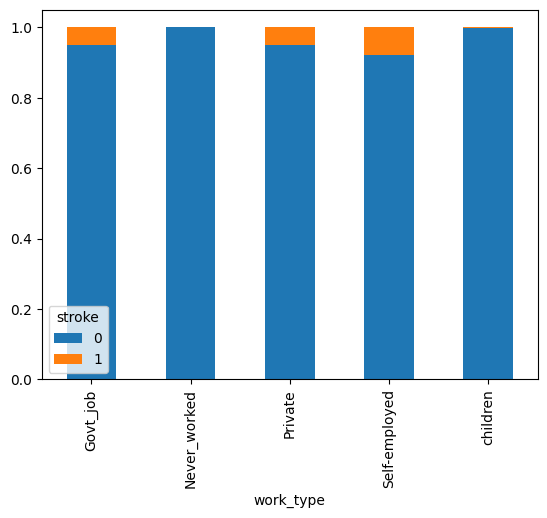

In [ ]:
(df.groupby('work_type')['stroke'].value_counts(normalize=True)
   .unstack('stroke').plot.bar(stacked=True)
)

**No sorprende que la mayor parte de casos sean  autónomos. Sí sorprende que funcionarios y sector privado tengan valores relativos similares**

<Axes: xlabel='Residence_type'>

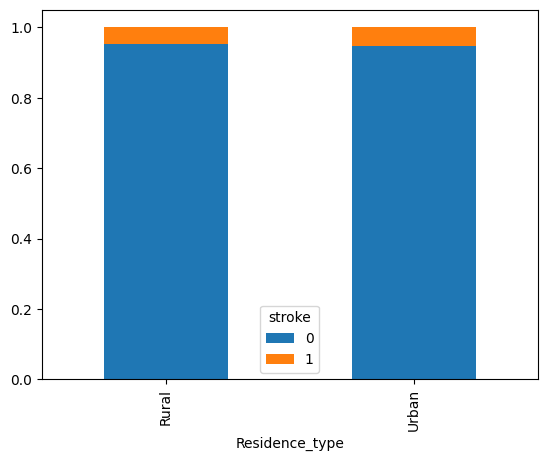

In [ ]:
# Veamos ahora por tipo de residecia
(df.groupby('Residence_type')['stroke'].value_counts(normalize=True)
   .unstack('stroke').plot.bar(stacked=True)
)

In [ ]:
residence_stroke = pd.crosstab(df.stroke, df.Residence_type, margins=True)
residence_stroke

Residence_type,Rural,Urban,All
stroke,,,
0,2340,2401,4741
1,114,134,248
All,2454,2535,4989


In [ ]:
res = relative_risk(residence_stroke.loc[1, "Urban"], residence_stroke.loc["All", "Urban"], residence_stroke.loc[1, "Rural"], residence_stroke.loc["All", "Urban"])
res

RelativeRiskResult(relative_risk=1.175438596491228, exposed_cases=134, exposed_total=2535, control_cases=114, control_total=2535)

In [ ]:
res.confidence_interval()

ConfidenceInterval(low=0.9213234566162115, high=1.4996425893635024)

In [ ]:
res.confidence_interval(confidence_level=0.8)

ConfidenceInterval(low=np.float64(1.0023721930674492), high=np.float64(1.3783860961796421))

**Influencia no concluyente, aunque ligeramente mayor riesgo en poblaciones urbanas. Podríamos esperar mayor impacto en lo urbano**

<Axes: xlabel='ever_married'>

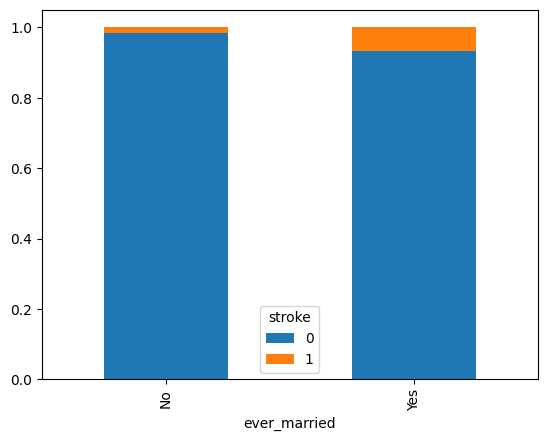

In [ ]:
# Veamos ahora por estado civil
(df.groupby('ever_married')['stroke'].value_counts(normalize=True)
   .unstack('stroke').plot.bar(stacked=True)
)

In [ ]:
married_stroke = pd.crosstab(df.stroke, df.ever_married, margins=True)
res = relative_risk(married_stroke.loc[1, "Yes"], married_stroke.loc["All", "Yes"], married_stroke.loc[1, "No"], married_stroke.loc["All", "No"])
print(res.relative_risk)
print(res.confidence_interval())

3.8476304227274665
ConfidenceInterval(low=np.float64(2.608188238993375), high=np.float64(5.676070326738232))


**Influencia obvia de estar casado con riesgo de infarto. Posiblemente se deba a un tipo de vida más sedentaria o a un mayor estrés familiar**

<Axes: xlabel='gender'>

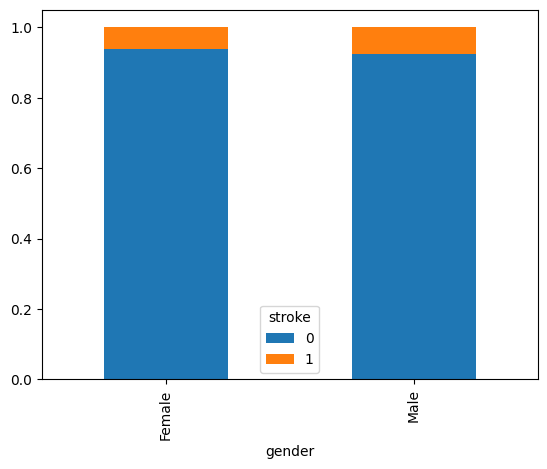

In [ ]:
# analisis bivariante genero-estado civil

# Veamos ahora por estado civil
(df[df.ever_married == "Yes"].groupby('gender')['stroke'].value_counts(normalize=True)
   .unstack('stroke').plot.bar(stacked=True)
)

<Axes: xlabel='gender'>

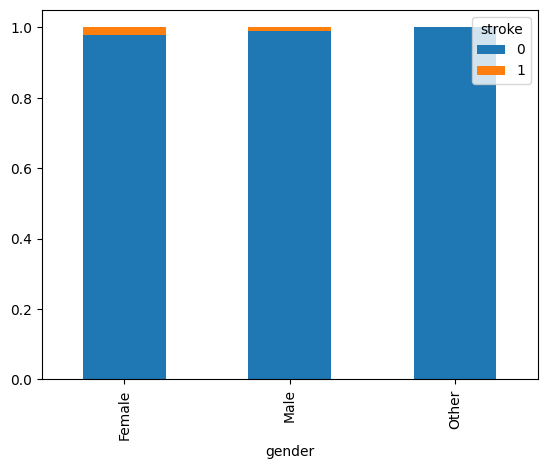

In [ ]:
# Veamos ahora por estado civil
(df[df.ever_married == "No"].groupby('gender')['stroke'].value_counts(normalize=True)
   .unstack('stroke').plot.bar(stacked=True)
)

In [ ]:
aux = df.loc[((df.ever_married == "Yes") & (df.stroke == 1)), "gender"].value_counts().reset_index()
aux["total"] = df.gender.value_counts().reset_index()["count"]

In [ ]:
aux

,gender,count,total
0,Female,120,Female
1,Male,100,Male


In [ ]:
aux["ratio"] = aux["count"]/aux["total"]

In [ ]:
aux

,gender,count,total,ratio
0,Female,120,2936,0.040872
1,Male,100,2052,0.048733


No concluyente, puesto que esperábamos un claro impacto entre género-estado civil y el riesgo de infarto

#Análisis del tabaco

In [ ]:
df.smoking_status.value_counts()

,count
smoking_status,
never smoked,1889
Unknown,1427
formerly smoked,885
smokes,788


<Axes: xlabel='smoking_status'>

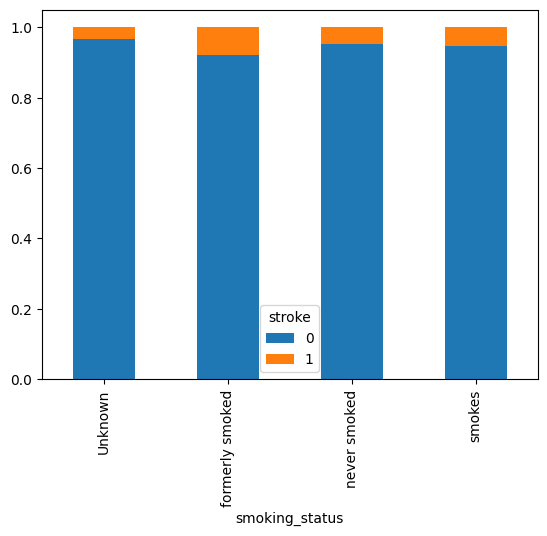

In [ ]:
# Veamos ahora por smoking_status
(df.groupby('smoking_status')['stroke'].value_counts(normalize=True)
   .unstack('stroke').plot.bar(stacked=True)
)

La categoria de mayor riesgo es fumador en el pasado. Quizas haya tambien una relación con la edad.

In [ ]:
# Vamos a calcular el riesgo relativo entre fumadores vs no fumadores

smoke_stroke = pd.crosstab(df[df.smoking_status != "Unknown"].stroke, df[df.smoking_status != "Unknown"].smoking_status, margins=True)

In [ ]:
smoke_stroke

smoking_status,formerly smoked,never smoked,smokes,All
stroke,,,,
0,815,1799,746,3360
1,70,90,42,202
All,885,1889,788,3562


In [ ]:
exposed_1 = smoke_stroke.loc[1, ["formerly smoked", "smokes"]].sum()
exposed_all = smoke_stroke.loc["All", ["formerly smoked", "smokes"]].sum()
control_1 = smoke_stroke.loc[1, "never smoked"]
control_all = smoke_stroke.loc["All", "never smoked"]

res = relative_risk(exposed_1, exposed_all, control_1, control_all)
print(res.relative_risk)
print(res.confidence_interval())

1.4051139005113897
ConfidenceInterval(low=np.float64(1.0731285453566415), high=np.float64(1.8398029592570215))


**Claramente existe un riesgo asociado a fumar**

<Axes: xlabel='age', ylabel='Density'>

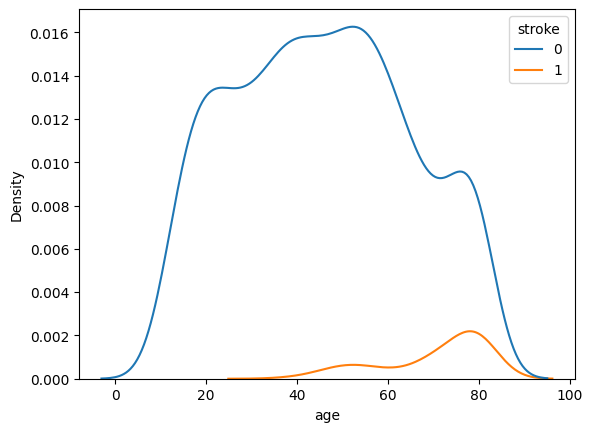

In [ ]:
sns.kdeplot(df.loc[df.smoking_status == "never smoked", ["age", "stroke"]], x="age", hue="stroke")

<Axes: xlabel='age', ylabel='Density'>

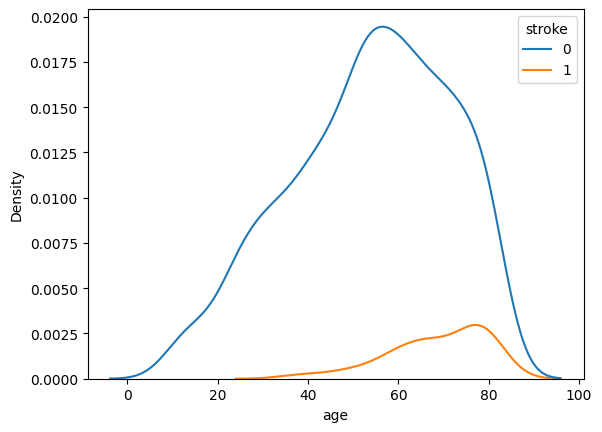

In [ ]:
# Veamos ahora la asociacion entre edad y fumadores
sns.kdeplot(df.loc[df.smoking_status == "formerly smoked", ["age", "stroke"]], x="age", hue="stroke")

<Axes: xlabel='age', ylabel='Density'>

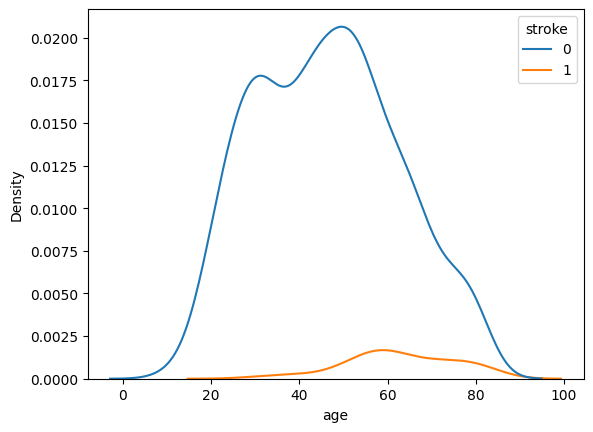

In [ ]:
# Veamos ahora la asociacion entre edad y smokes
sns.kdeplot(df.loc[df.smoking_status == "smokes", ["age", "stroke"]], x="age", hue="stroke")

Parece haber mucho ruido de fondo con la edad. Veamos qué pasa para edad > 37, que era la edad minima para empezar a haber infartos

<Axes: xlabel='age', ylabel='Density'>

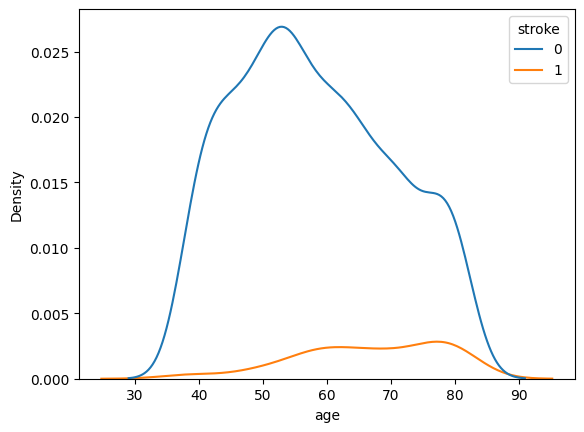

In [ ]:
sns.kdeplot(df.loc[(df.age > 37) & ((df.smoking_status == "formerly smoked") | (df.smoking_status == "smokes")), ["age", "stroke"]], x="age", hue="stroke")

Los formerly smoked son gente de alta edad, donde es difícil concluir cuál es la condición de mayor riesgo, si la edad o haber sido fumadores.
En cambio, en los casos que fuman actualmente, sí se ve cómo se adelanta la edad de sufrir infarto.

# Supercandidatos

Bonus final, a ver si sale algo

In [ ]:
super_candidates = df[(df.age > 40) & (df.heart_disease == 1) & (df.hypertension == 1) & (df.ever_married == "Yes") &
   (df.smoking_status.isin(["smokes", "formerly smoked"]))]

In [ ]:
len(super_candidates)

32

In [ ]:
df.loc[df.index.isin(super_candidates.index), "super_candidate"] = 1
df = df.fillna(0)

In [ ]:
cand = pd.crosstab(df.stroke, df.super_candidate, margins=True)

exposed_1 = cand.loc[1, 1]
exposed_all = cand.loc["All", 1]
control_1 = cand.loc[1, 0]
control_all = cand.loc["All", 0]

res = relative_risk(exposed_1, exposed_all, control_1, control_all)
print(res.relative_risk)
print(res.confidence_interval())

5.163541666666667
ConfidenceInterval(low=np.float64(2.7981261848336305), high=np.float64(9.528577620236252))


In [ ]:
res.confidence_interval(confidence_level=0.999)

ConfidenceInterval(low=1.846005667444596, high=14.44316396943185)